In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from src.data import animals, load_data, train_test_split
from src.pca import PCA
from src.models import NMC, KNN, LDA
from src.evaluation import cross_validate, cv_pca_curve, confusion_matrix

X, y = load_data(animals)
print(X.shape, y.shape)
print(np.bincount(y))
print(X.min(), X.max())

(30000, 784) (30000,)
[3000 3000 3000 3000 3000 3000 3000 3000 3000 3000]
0.0 1.0


In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y)
print(X_train.shape, X_test.shape)
print(np.bincount(y_train))

(24000, 784) (6000, 784)
[2421 2378 2399 2382 2405 2407 2372 2406 2402 2428]


## Phase 1: Explore the drawings

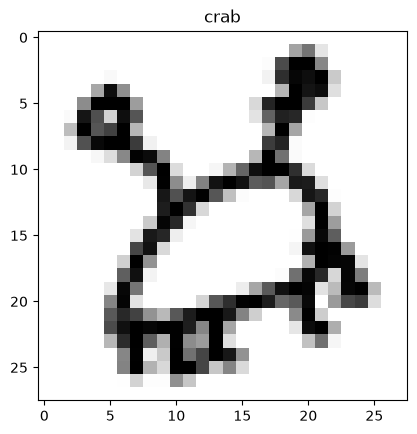

In [3]:
i = 12345
plt.imshow(X[i].reshape(28, 28), cmap="gray_r")
plt.title(animals[y[i]])
plt.show()

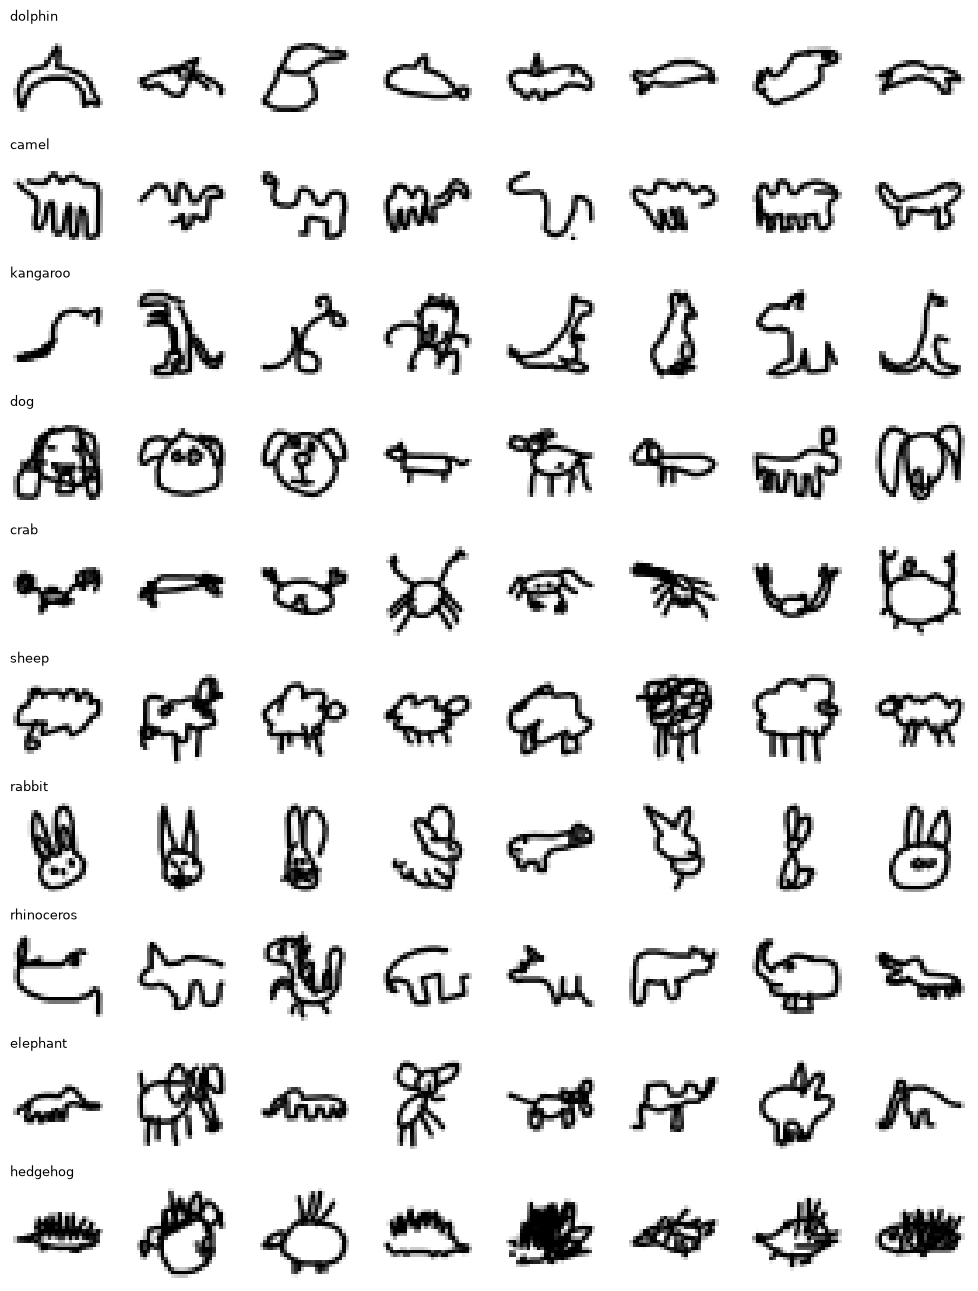

In [4]:
fig, axes = plt.subplots(len(animals), 8, figsize=(10, 13))
for c, name in enumerate(animals):
    examples = X_train[y_train == c][:8]
    for j in range(8):
        axes[c, j].imshow(examples[j].reshape(28, 28), cmap="gray_r")
        axes[c, j].axis("off")
    axes[c, 0].set_title(name, loc="left", fontsize=9)
plt.tight_layout()
plt.show()

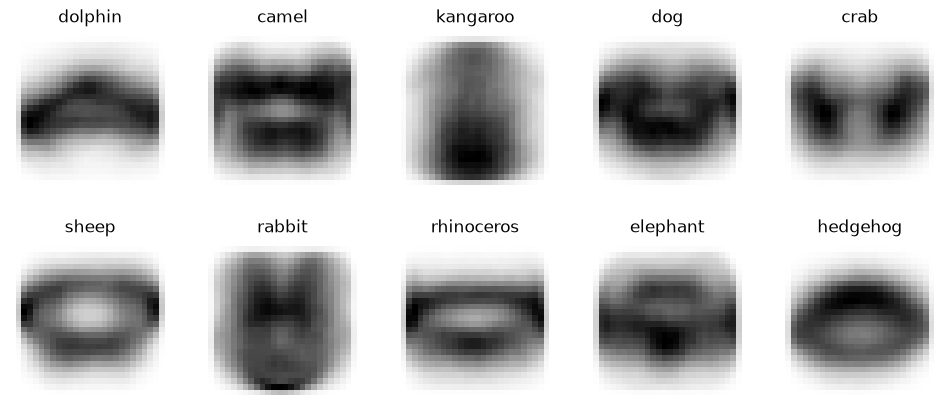

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for c, ax in enumerate(axes.flat):
    mean_img = X_train[y_train == c].mean(axis=0)
    ax.imshow(mean_img.reshape(28, 28), cmap="gray_r")
    ax.set_title(animals[c])
    ax.axis("off")
plt.show()

## Phase 2: PCA

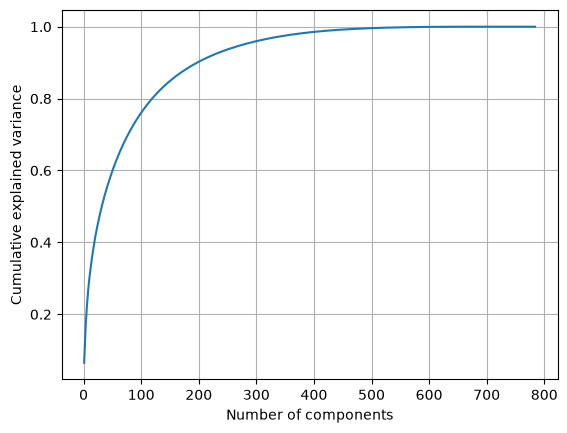

80% of variance: 119 components
90% of variance: 198 components
95% of variance: 277 components


In [3]:
pca = PCA(k=150).fit(X_train)

cum = np.cumsum(pca.explained)
plt.plot(np.arange(1, len(cum) + 1), cum)
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.grid(True)
plt.show()

for target in [0.8, 0.9, 0.95]:
    print(f"{target:.0%} of variance: {np.argmax(cum >= target) + 1} components")

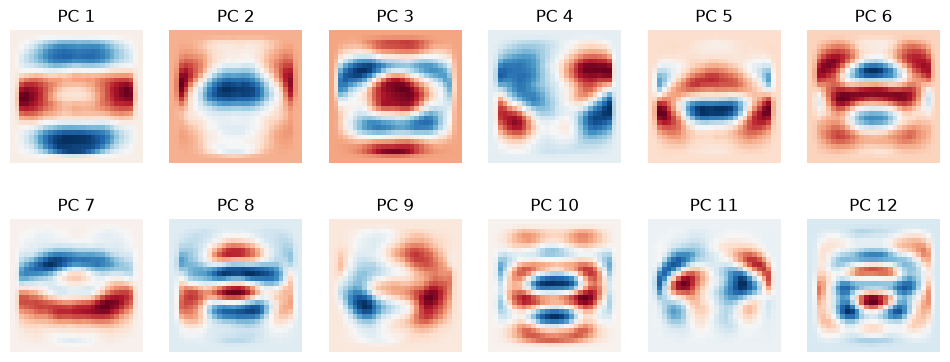

In [7]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(pca.components[i].reshape(28, 28), cmap="RdBu")
    ax.set_title(f"PC {i+1}")
    ax.axis("off")
plt.show()

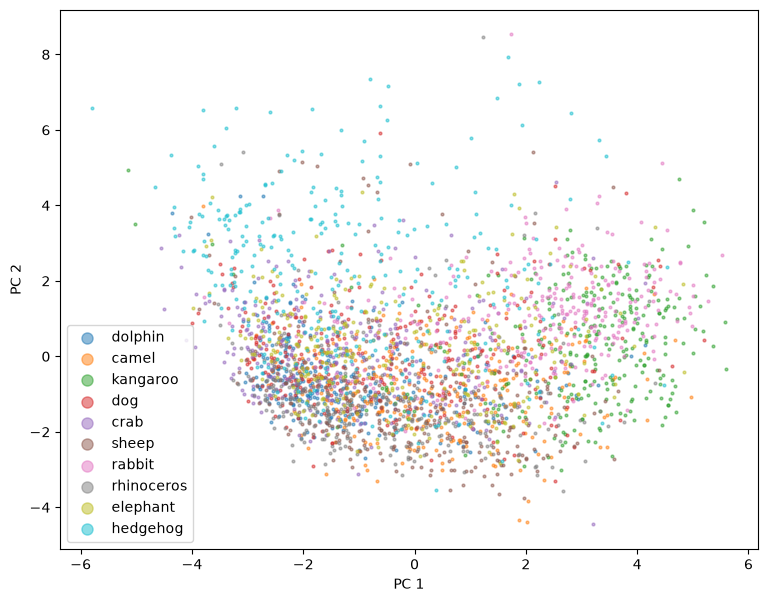

In [8]:
Z = pca.transform(X_train)
plt.figure(figsize=(9, 7))
for c, name in enumerate(animals):
    pts = Z[y_train == c][:300]
    plt.scatter(pts[:, 0], pts[:, 1], s=4, alpha=0.5, label=name)
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.legend(markerscale=4)
plt.show()

In [3]:
# split off a validation set from the TRAINING data; the test set stays untouched
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_frac=0.2, seed=1)

# PCA fitted on the training part only, then applied to both
pca40 = PCA(k=40).fit(X_tr)
Z_tr = pca40.transform(X_tr)
Z_val = pca40.transform(X_val)

# Nearest Mean Classifier
nmc = NMC().fit(Z_tr, y_tr)
acc = np.mean(nmc.predict(Z_val) == y_val)
print(f"NMC with 40 PCA components: {acc:.1%}")

NMC with 40 PCA components: 48.1%


In [4]:
import time

for k in [12, 15, 20, 25]:
    t = time.time()
    knn = KNN(k=k).fit(Z_tr, y_tr)
    acc = np.mean(knn.predict(Z_val) == y_val)
    print(f"KNN k={k}: {acc:.1%}  ({time.time() - t:.1f} s)")

KNN k=12: 65.8%  (2.0 s)
KNN k=15: 65.9%  (1.8 s)
KNN k=20: 66.2%  (1.6 s)
KNN k=25: 65.9%  (1.5 s)


In [5]:
lda = LDA().fit(Z_tr, y_tr)
print(f"LDA with 40 PCA components: {np.mean(lda.predict(Z_val) == y_val):.1%}")

LDA with 40 PCA components: 50.6%


fold 1/5 done
fold 2/5 done
fold 3/5 done
fold 4/5 done
fold 5/5 done


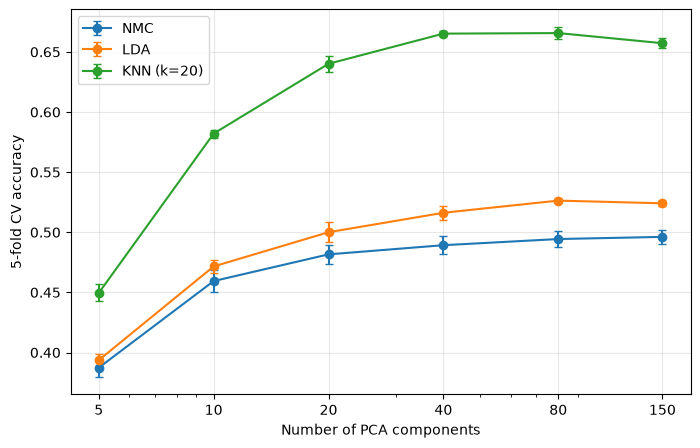

In [8]:
sizes = [5, 10, 20, 40, 80, 150]
models = {
    "NMC": lambda: NMC(),
    "LDA": lambda: LDA(),
    "KNN (k=20)": lambda: KNN(k=20),
}
results = cv_pca_curve(models, sizes, X_train, y_train)

plt.figure(figsize=(8, 5))
for name, (means, stds) in results.items():
    plt.errorbar(sizes, means, yerr=stds, marker="o", capsize=3, label=name)
plt.xscale("log")
plt.xticks(sizes, sizes)
plt.xlabel("Number of PCA components")
plt.ylabel("5-fold CV accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

KNN is by far the best classifier. It peaks at around 66.5% with 40-80 components, then drops again slightly .

In [9]:
knn_models = {f"k={k}": (lambda k=k: KNN(k=k)) for k in [5, 10, 15, 20, 30, 50]}
knn_results = cv_pca_curve(knn_models, [40, 80], X_train, y_train)

for name, (means, stds) in knn_results.items():
    print(f"{name:5s}  40 comp: {means[0]:.1%} ± {stds[0]:.1%}   "
          f"80 comp: {means[1]:.1%} ± {stds[1]:.1%}")

fold 1/5 done
fold 2/5 done
fold 3/5 done
fold 4/5 done
fold 5/5 done
k=5    40 comp: 65.1% ± 0.4%   80 comp: 65.9% ± 0.4%
k=10   40 comp: 66.1% ± 0.6%   80 comp: 67.0% ± 0.4%
k=15   40 comp: 66.3% ± 0.4%   80 comp: 66.8% ± 0.5%
k=20   40 comp: 66.5% ± 0.2%   80 comp: 66.6% ± 0.5%
k=30   40 comp: 66.1% ± 0.3%   80 comp: 65.9% ± 0.3%
k=50   40 comp: 65.0% ± 0.2%   80 comp: 64.9% ± 0.4%


KNN is not very sensitive to k: k = 10–20 at 40–80 components all score 66–67%. I chose k = 20 with 40 components: within the error bars of the best score, and simpler and faster.

In [6]:
final = {
    "NMC": (lambda: NMC(), 80),
    "LDA": (lambda: LDA(), 80),
    "KNN": (lambda: KNN(k=20), 40),
}

test_preds = {}
for name, (make_model, n) in final.items():
    pca = PCA(n).fit(X_train)                                  # PCA on all training data
    model = make_model().fit(pca.transform(X_train), y_train)  # train on all training data
    test_preds[name] = model.predict(pca.transform(X_test))    # predict the test set once
    acc = np.mean(test_preds[name] == y_test)
    print(f"{name}: test accuracy {acc:.1%}")

NMC: test accuracy 48.8%
LDA: test accuracy 52.7%
KNN: test accuracy 66.9%


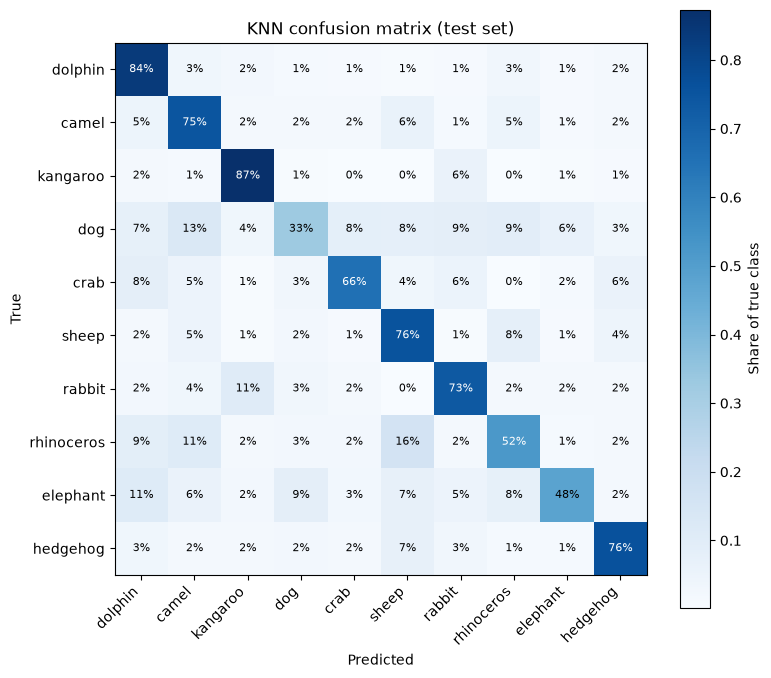

rhinoceros → sheep: 16%
dog → camel: 13%
elephant → dolphin: 11%
rhinoceros → camel: 11%
rabbit → kangaroo: 11%


In [7]:
cm = confusion_matrix(y_test, test_preds["KNN"], len(animals))
cm_norm = cm / cm.sum(axis=1, keepdims=True)      # each row as shares adding to 100%

plt.figure(figsize=(8, 7))
plt.imshow(cm_norm, cmap="Blues")
plt.colorbar(label="Share of true class")
plt.xticks(range(len(animals)), animals, rotation=45, ha="right")
plt.yticks(range(len(animals)), animals)
plt.xlabel("Predicted")
plt.ylabel("True")
for i in range(len(animals)):
    for j in range(len(animals)):
        plt.text(j, i, f"{cm_norm[i, j]:.0%}", ha="center", va="center",
                 color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=8)
plt.title("KNN confusion matrix (test set)")
plt.tight_layout()
plt.show()

# the 5 most common mistakes
off = cm_norm.copy()
np.fill_diagonal(off, 0)
for idx in np.argsort(off, axis=None)[::-1][:5]:
    i, j = divmod(idx, len(animals))
    print(f"{animals[i]} → {animals[j]}: {off[i, j]:.0%}")

Easy: kangaroo 87%, dolphin 84%
Middle: hedgehog 76%, sheep 76%, camel 75%, rabbit 73%, crab 66%
Hard: rhinoceros 52%, elephant 48%, dog 33%